# Exploratory Data Analysis
## Peaks

In [551]:
from himalayan_db_pipeline.config import PROJECT_ROOT
from himalayan_db_pipeline.utils import read_dbf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

In [552]:
data_dir = PROJECT_ROOT / "data"
df = read_dbf(data_dir / "peaks.DBF")

### Overview
- deimensions
- data types
- missing/unique values
- primary key

In [553]:
df.shape

(503, 25)

In [554]:
df.dtypes.value_counts()

str      15
int64     7
bool      3
Name: count, dtype: int64

In [555]:
pd.DataFrame({
  "column_name": df.columns,
  "data_type": [df[col].dtype for col in df.columns],
  "nan_count": [df[col].isna().sum() for col in df.columns],
  "nan_perc": [df[col].isna().sum() / len(df[col]) for col in df.columns],
  "unique_values": [df[col].nunique() for col in df.columns]
})

,column_name,data_type,nan_count,nan_perc,unique_values
0,peakid,str,0,0.000000,503
1,pkname,str,0,0.000000,503
2,pkname2,str,244,0.485089,256
3,location,str,1,0.001988,421
4,heightm,int64,0,0.000000,433
5,heightf,int64,0,0.000000,433
6,himal,int64,0,0.000000,20
7,region,int64,0,0.000000,7
8,open,bool,0,0.000000,2
9,unlisted,bool,0,0.000000,2


In [556]:
# check if peakid is a valid PK variable
assert df.peakid.notna().all()
assert df.peakid.is_unique

### Data Quality
#### Text
- missing values
- cardinality
- formatting consistency

In [557]:
df.select_dtypes(include=[str]).head(5)

,peakid,pkname,pkname2,location,trekyear,restrict,peakmemo,pyear,pexpid,psmtdate,pcountry,psummiters,psmtnote,refermemo,photomemo
0,AMAD,Ama Dablam,Amai Dablang,Khumbu Himal,NaN,NaN,"Other map altitudes:\r\n 6814m - HMG-MT, HMG...",1961,AMAD61101,Mar 13,"New Zealand, USA, UK","Mike Gill, Wally Romanes, Barry Bishop, Michae...",NaN,NaN,W Face (High 126:5 May 1993)\r\nSE Face (High ...
1,AMPG,Amphu Gyabjen,Amphu Gyabien,Khumbu Himal (N of Ama Dablam),NaN,Opened in 2002,"Other map altitudes:\r\n 5630m - HMG-Finn, N...",1953,AMPG53101,Apr 11,UK,"John Hunt, Tom Bourdillon",NaN,NaN,NaN
2,ANN1,Annapurna I,NaN,Annapurna Himal,NaN,NaN,"Other map altitudes:\r\n 8091m - HMG-MT, HMG...",1950,ANN150101,Jun 03,France,"Maurice Herzog, Louis Lachenal",NaN,Dyhrenfurth history 1950-1977 (MM 58:44-47 Nov...,S Face (High 122:3 Jan 1993) (Beghin accident)...
3,ANN2,Annapurna II,NaN,Annapurna Himal,NaN,NaN,"Other map altitudes:\r\n 7937m - HMG-MT, HMG...",1960,ANN260101,May 17,"UK, Nepal","Richard Grant, Chris Bonington, Ang Nyima Sherpa",NaN,Dyhrenfurth history 1960-1976 (MM 51:36-37 Sep...,N Face (MM 51:36 Sep 1976)
4,ANN3,Annapurna III,NaN,Annapurna Himal,NaN,NaN,"Other map altitudes:\r\n 7555m - HMG-MT, HMG...",1961,ANN361101,May 06,India,"Mohan S. Kohli, Sonam Gyatso, Sonam Girmi",NaN,NaN,S Side (MM 125:11 Jan 1989)\r\nSW Face (MM 71:...


In [558]:
df.select_dtypes(include=[str]).isna().mean().sort_values(ascending=False)

refermemo     0.962227
trekyear      0.938370
psmtnote      0.846918
photomemo     0.844930
pkname2       0.485089
restrict      0.399602
psmtdate      0.254473
pexpid        0.248509
pcountry      0.246521
pyear         0.244533
psummiters    0.021869
peakmemo      0.015905
location      0.001988
peakid        0.000000
pkname        0.000000
dtype: float64

##### Local names

In [559]:
df.pkname2.dropna().head(10)

0                   Amai Dablang
1                  Amphu Gyabien
8     Annapurna Dakshin, Moditse
13                      Morimoto
14                 Damodar Himal
17                 Changla Himal
18                       Peak 23
21             Chobutse, Tsoboje
22      Tsolatse, Jobo Lhaptshan
24                    Chulu East
Name: pkname2, dtype: str

- The _pkname2_ variable contains non-atomic entries with comma-separated values
- Modeling will require the creation of a separate tables.

##### Trek year

In [560]:
df.trekyear.dtype

<StringDtype(na_value=nan)>

In [561]:
df.trekyear.value_counts()

trekyear
1978    20
2002    10
20       1
Name: count, dtype: int64

- _trekyear_ has a high proportion of missing values
- numerical strings with inconsistent formatting
- **_trekyear_ should be modeled as integer**

##### Memo variables

In [562]:
df[['refermemo', 'photomemo', 'peakmemo']].head()

,refermemo,photomemo,peakmemo
0,NaN,W Face (High 126:5 May 1993)\r\nSE Face (High ...,"Other map altitudes:\r\n 6814m - HMG-MT, HMG..."
1,NaN,NaN,"Other map altitudes:\r\n 5630m - HMG-Finn, N..."
2,Dyhrenfurth history 1950-1977 (MM 58:44-47 Nov...,S Face (High 122:3 Jan 1993) (Beghin accident)...,"Other map altitudes:\r\n 8091m - HMG-MT, HMG..."
3,Dyhrenfurth history 1960-1976 (MM 51:36-37 Sep...,N Face (MM 51:36 Sep 1976),"Other map altitudes:\r\n 7937m - HMG-MT, HMG..."
4,NaN,S Side (MM 125:11 Jan 1989)\r\nSW Face (MM 71:...,"Other map altitudes:\r\n 7555m - HMG-MT, HMG..."


- memo variable entries are free-form, unstructured text
- difficult to parse and carry little analytical value
- **memo variables (_refermemo_, _photomemo_, _peakmemo) to be ignored in data models**

##### Initial ascent variables

In [563]:
df[['pexpid', 'pyear', 'psmtdate', 'psummiters', 'psmtnote', 'pcountry']].head()

,pexpid,pyear,psmtdate,psummiters,psmtnote,pcountry
0,AMAD61101,1961,Mar 13,"Mike Gill, Wally Romanes, Barry Bishop, Michae...",NaN,"New Zealand, USA, UK"
1,AMPG53101,1953,Apr 11,"John Hunt, Tom Bourdillon",NaN,UK
2,ANN150101,1950,Jun 03,"Maurice Herzog, Louis Lachenal",NaN,France
3,ANN260101,1960,May 17,"Richard Grant, Chris Bonington, Ang Nyima Sherpa",NaN,"UK, Nepal"
4,ANN361101,1961,May 06,"Mohan S. Kohli, Sonam Gyatso, Sonam Girmi",NaN,India


In [564]:
df[['pexpid', 'pyear', 'psmtdate', 'psummiters', 'psmtnote', 'pcountry']].isna().mean()

pexpid        0.248509
pyear         0.244533
psmtdate      0.254473
psummiters    0.021869
psmtnote      0.846918
pcountry      0.246521
dtype: float64

In [565]:
df[['pexpid', 'pyear', 'psmtdate', 'psummiters', 'psmtnote', 'pcountry']].nunique()

pexpid        378
pyear          77
psmtdate      163
psummiters    369
psmtnote       72
pcountry       86
dtype: int64

In [566]:
try:
  pd.to_datetime(df.psmtdate, format='%b %d')
except ValueError as e:
  print(e)

time data "Nov" doesn't match format "%b %d". You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.


#### Numeric variables
- missing values
- outliers

In [567]:
df.select_dtypes(include=['number']).head(5)

,heightm,heightf,himal,region,phost,pstatus,pseason
0,6814,22356,12,2,1,2,1
1,5630,18471,12,2,1,2,1
2,8091,26545,1,5,1,2,1
3,7937,26040,1,5,1,2,1
4,7555,24787,1,5,1,2,1


In [568]:
df.select_dtypes(include=['number']).describe()

,heightm,heightf,himal,region,phost,pstatus,pseason
count,503.000000,503.000000,503.000000,503.000000,503.000000,503.000000,503.000000
mean,6633.912525,21764.817097,10.417495,3.827038,2.170974,1.767396,1.612326
std,566.623177,1859.006870,5.548110,2.151601,1.531408,0.422913,1.265071
min,5407.000000,17740.000000,1.000000,1.000000,0.000000,1.000000,0.000000
25%,6225.500000,20425.000000,6.000000,2.000000,1.000000,2.000000,1.000000
50%,6530.000000,21424.000000,11.000000,4.000000,1.000000,2.000000,1.000000
75%,6874.500000,22554.000000,15.000000,6.000000,4.000000,2.000000,3.000000
max,8849.000000,29032.000000,20.000000,7.000000,6.000000,2.000000,4.000000


##### Height

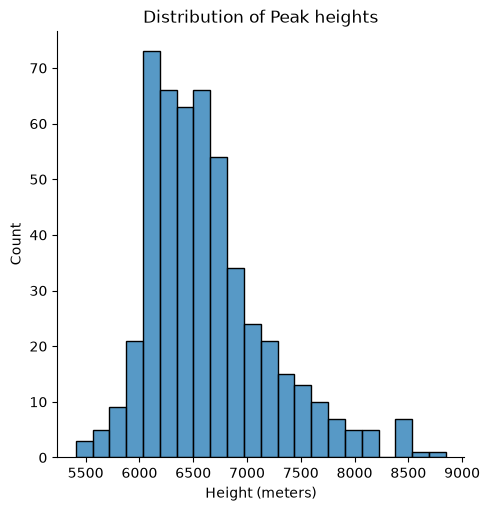

In [569]:
sns.displot(data=df, x="heightm")
plt.title("Distribution of Peak heights")
plt.xlabel("Height (meters)")
plt.show()

In [570]:
# check for inconsistencies in imperial to metric conversion
e = .001
ratios = df.heightf / df.heightm
assert (ratios.max() - ratios.min()) < e

In [571]:
df.heightm.describe()

count     503.000000
mean     6633.912525
std       566.623177
min      5407.000000
25%      6225.500000
50%      6530.000000
75%      6874.500000
max      8849.000000
Name: heightm, dtype: float64

##### Range

In [572]:
df.himal.isna().mean()

np.float64(0.0)

In [573]:
df.himal.describe()

count    503.000000
mean      10.417495
std        5.548110
min        1.000000
25%        6.000000
50%       11.000000
75%       15.000000
max       20.000000
Name: himal, dtype: float64

##### Status

In [539]:
df.pstatus.value_counts(normalize=True)

pstatus
2    0.767396
1    0.232604
Name: proportion, dtype: float64

#### Boolean

In [540]:
df.select_dtypes(include=[bool]).head(5)

,open,unlisted,trekking
0,True,False,False
1,True,False,False
2,True,False,False
3,True,False,False
4,True,False,False


In [541]:
df.select_dtypes(include=[bool]).mean()

open        0.805169
unlisted    0.127237
trekking    0.065606
dtype: float64

### Analysis
- distribution
- relationships

In [542]:
df['range'] = df.himal.fillna('0')
df.range = df.range.astype(int)

In [543]:
df.range = pd.Categorical(
  df.range.astype(str),
  categories=[str(x) for x in df.range.sort_values().unique()]
)
df.region = pd.Categorical(df.region, categories=df.region.unique())

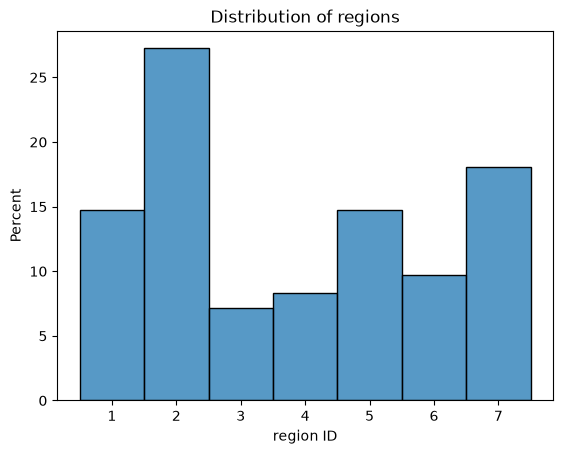

In [544]:
sns.histplot(data=df, x="region", binwidth=1, stat="percent")
plt.title("Distribution of regions")
plt.xlabel("region ID")
plt.show()

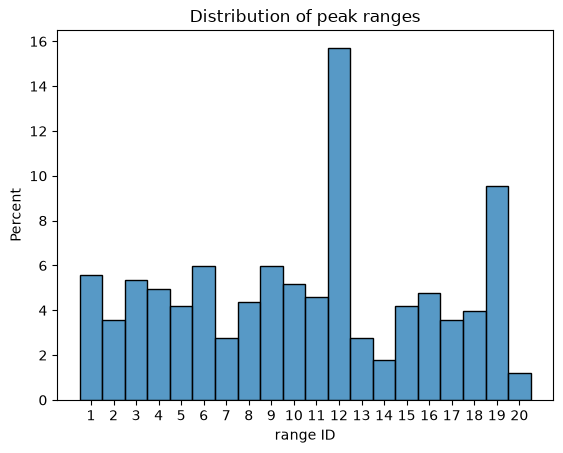

In [545]:
sns.histplot(data=df, x="range", stat="percent")
plt.title("Distribution of peak ranges")
plt.xlabel("range ID")
plt.show()

In [548]:
df.location.value_counts().sort_values(ascending=False)[:10]

location
Ohmi Kangri Himal (WNW of Kangchenjunga)             6
Nalakankar Himal (on W Nepal/Tibetan border)         5
Annapurna Himal                                      4
Khumbu Himal (NE of Cho Oyu on Tibetan border)       3
Shringi Himal (S of Tobsar)                          3
Kanti Himal (NW of Kanti Himal on Tibetan border)    3
Mustang Himal (S of Mansail on Tibetan border)       3
Khumbu Himal (SW of Gokyo Lake)                      3
Rolwaling Himal (N of Tesi Laptsa)                   3
Annapurna-Nilgiri Himal (NW of Annapurna I)          3
Name: count, dtype: int64

##### Peak to location

In [33]:
print("Most peaks in one location:", df.groupby('location')['peakid'].nunique().max())
print("Most locations associated with one peak:", df.groupby('peakid')['location'].nunique().max())

Most peaks in one location: 6
Most locations associated with one peak: 1


##### Peak to range

In [34]:
print("Most peaks in one range:", df.groupby('himal')['peakid'].nunique().max())
print("Most ranges associated with one peak:", df.groupby('peakid')['himal'].nunique().max())

Most peaks in one range: 79
Most ranges associated with one peak: 1


##### Peak to region

In [35]:
print("Most peaks in one region:", df.groupby('region')['peakid'].nunique().max())
print("Most regions associated with one peak:", df.groupby('peakid')['region'].nunique().max())

Most peaks in one region: 137
Most regions associated with one peak: 1


##### Location to range

In [36]:
print("Most locations in one range:", df.groupby('himal')['location'].nunique().max())
print("Most ranges associated with one location:", df.groupby('location')['himal'].nunique().max())

Most locations in one range: 64
Most ranges associated with one location: 1


##### Location to region

In [37]:
print("Most locations in one region:", df.groupby('region')['location'].nunique().max())
print("Most regions associated with one location:", df.groupby('location')['region'].nunique().max())

Most locations in one region: 113
Most regions associated with one location: 1


##### Range to region

In [38]:
print("Most ranges in one region:", df.groupby('region')['himal'].nunique().max())
print("Most regions associated with one range:", df.groupby('himal')['region'].nunique().max())

Most ranges in one region: 5
Most regions associated with one range: 2


In [39]:
df.loc[df.location.isna()]

,peakid,pkname,pkname2,location,heightm,heightf,himal,region,open,unlisted,...,peakmemo,pyear,pseason,pexpid,psmtdate,pcountry,psummiters,psmtnote,refermemo,photomemo
461,SANK,Sano Kailash,NaN,NaN,6452,21168,3,5,False,True,...,Other map altitudes:\r\n 6425m - Nepa\r\n ...,2019,1,SANK19101,Apr 28,"Austria, Nepal","Wolfgang Drexler, Lawang Tamang",NaN,NaN,NaN


> - transitive relationships through nested geographical data: _range > location > peak_
> - one peak has missing location entry
> - many-to-many relationship between range and region